# Task 2.2: how often does it phase flip?

**In plain words.** A phase flip keeps the light in its valley but scrambles the relative sign between the two valleys: the even cat $|C_+\rangle$ turns into the odd cat $|C_-\rangle$. Every lost photon does this, because $a|C_\pm\rangle \propto |C_\mp\rangle$. Its rate is the slowest nonzero eigenvalue in the "even" block of the Liouvillian. We read it off directly, and cross-check it against the decay of memory parity starting from $|C_+\rangle$.

**Prediction before simulating.** Photons are lost at rate $\kappa_a\bar n$ with $\bar n \approx \alpha^2$, and each loss flips the parity, so the parity decays at $2\kappa_a\alpha^2$. Including the small difference between the photon numbers of the even and odd cats gives $\Gamma_Z = 2\kappa_a\alpha^2\coth 2\alpha^2$: a straight line for large cats.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display
import pandas as pd
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from research.s2 import notebook_figs as F          # loads saved results/s2/*.json, draws the figures
from research.s2.notebook_figs import load, nominal, largest
import io
from contextlib import redirect_stdout
show = lambda name, w=1000: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))

In [2]:
with redirect_stdout(io.StringIO()):
    F.phase_flips()

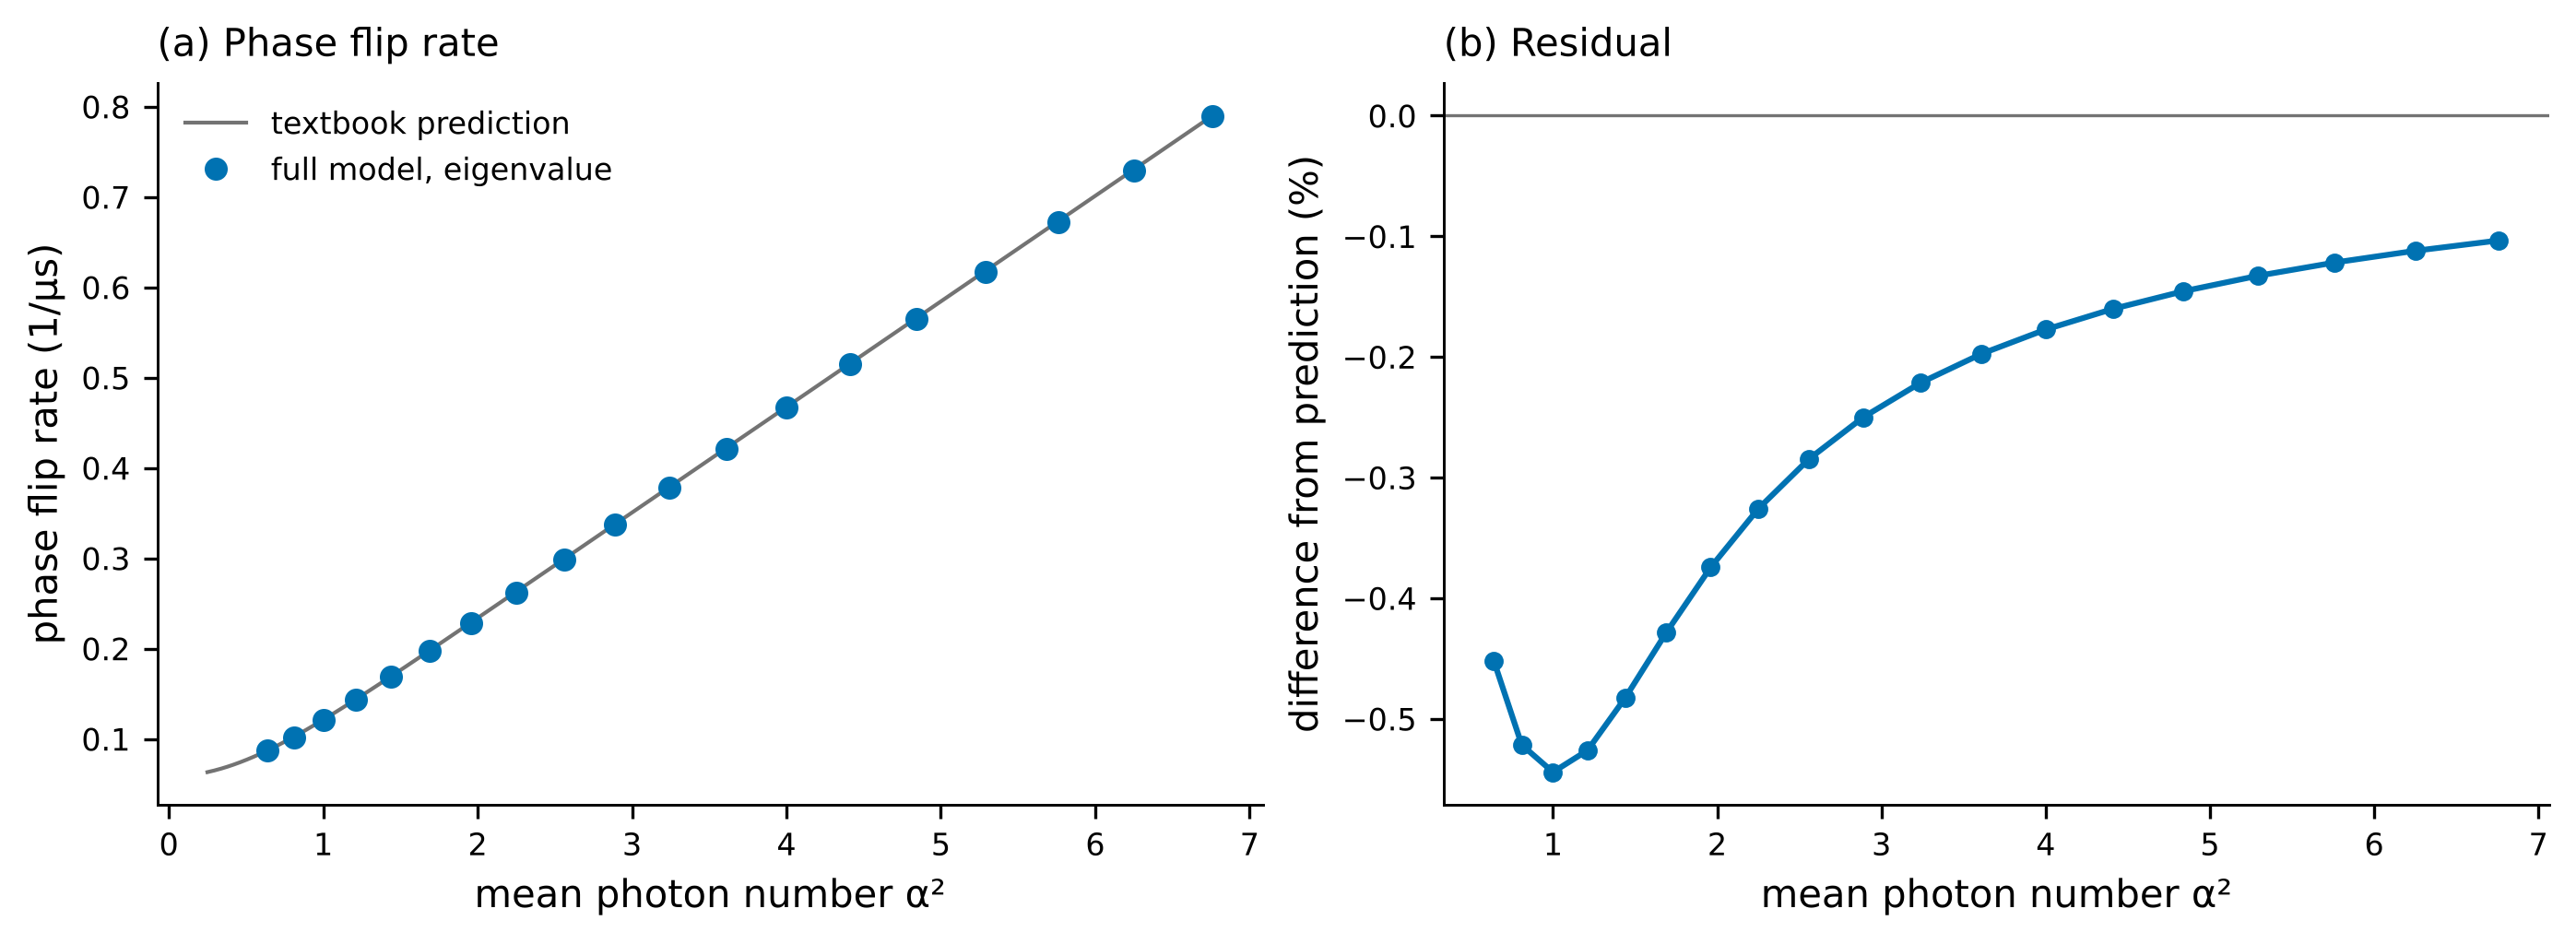

In [3]:
show('task_2_2_phase_flips')

**Phase flip rate against the textbook prediction.** (a) Phase flip rate $\Gamma_Z$ against mean photon number $\alpha^2$, from the slowest nonzero even-parity eigenvalue of the full memory + buffer model (blue circles, largest truncation at each $\alpha$), and the prediction $2\kappa_a\alpha^2\coth 2\alpha^2$ (grey line). No parameter is fitted. (b) Relative difference from the prediction, in percent. The full model is 0.1–0.55% below it everywhere; the deviation is largest near $\alpha^2 \approx 1$, where the two valleys still overlap, and shrinks for large cats.

In [4]:
ALPHAS = (1.0, 1.4, 1.8, 2.1, 2.4)
best = largest(d for d in load('gx_two_*.json') if nominal(d) and 'gamma_z_eig' in d)
pd.DataFrame([{'α': a, 'average photons α²': round(a * a, 2), 'phase flip rate (1/µs)': round(d['gamma_z_eig'], 4),
               'one flip every (µs)': round(1 / d['gamma_z_eig'], 2)} for a, d in best.items() if a in ALPHAS])

,α,average photons α²,phase flip rate (1/µs),one flip every (µs)
0,1.0,1.00,0.1206,8.29
1,1.4,1.96,0.2284,4.38
2,1.8,3.24,0.3778,2.65
3,2.1,4.41,0.5146,1.94
4,2.4,5.76,0.6723,1.49


**Result.** Phase flips grow **in direct proportion to the photon number**: the slope is 0.991 × the textbook $2\kappa_a$. At $\alpha = 2.1$ the qubit phase flips about every 2 µs. This is the error the repetition code must correct, and it is why bigger cats are not free: bit flips fall exponentially with $\alpha^2$ while phase flips grow only linearly.

## Numerical diagnostics

The two largest truncations at each $\alpha$, and an independent time-domain check: the eigenvalue and a fit to the parity decay of $|C_+\rangle$ agree to five digits (0.51455 vs 0.51456 per µs at $\alpha = 2.1$).

In [5]:
def two_largest(rows, key):
    by = {}
    for d in rows:
        by.setdefault(round(d['alpha'], 2), []).append(d)
    out = []
    for a, ds in sorted(by.items()):
        ds = sorted(ds, key=lambda d: d['na'] * d['nb'])
        if len(ds) >= 2 and a in ALPHAS:
            lo, hi = ds[-2], ds[-1]
            out.append({'α': a, 'previous size': f"{lo['na']}×{lo['nb']}", 'largest size': f"{hi['na']}×{hi['nb']}",
                        'rate (largest)': f"{hi[key]:.3e}", 'change': f"{abs(hi[key] / lo[key] - 1):.1%}"})
    return pd.DataFrame(out)

In [6]:
two_largest([d for d in load('gx_two_*.json') if nominal(d) and 'gamma_z_eig' in d], 'gamma_z_eig')

,α,previous size,largest size,rate (largest),change
0,1.0,20×8,24×8,1.206e-01,0.0%
1,1.4,22×8,26×8,2.284e-01,0.0%
2,1.8,26×8,30×8,3.778e-01,0.0%
3,2.1,28×8,32×8,5.146e-01,0.0%
4,2.4,32×8,36×8,6.723e-01,0.0%
